# Submission details
**Course:** Digital Image Processing (DIP) — Lab 11B &nbsp;|&nbsp; **Name:** ____________________ &nbsp;|&nbsp; **Roll No.:** ____________________

**What is in this notebook**
* Sections 1–11: the original lab pipeline, run with the default student controls (`sample_cat`, 32×32, 128 hidden, 16 latent, `relu`, 180 epochs), with all outputs saved.
* **Experiments A–F** (new, placed before the viva questions): each viva question 1–8 is backed by a measured experiment, run on freshly initialised, seeded networks so nothing disturbs the model trained in Sections 5–10.
* **Section 13**: written answers to the viva questions, and **Section 14**: conclusion.

Everything runs top-to-bottom with *Runtime → Run all* (CPU is enough; total run time is a few minutes).

# DIP Lab 11B — Fully Connected Autoencoder (FCNN-AE)
### A companion to Lab 11A (pretrained ViT–MAE) | Colab, train from scratch

**Goal:** experience the whole neural-network pipeline: RGB image → flatten → dense encoder → latent vector → dense decoder → reshaped image, plus trainable weights, biases, nonlinearities, forward/backward propagation, epochs, loss and image quality.

**Key distinction:** Unlike **Lab 11A (pretrained MAE)**, this lab trains an FCNN **from random weights** on the images you select. It does **not** contain Transformer attention or a pretrained image prior. Therefore, it cannot be expected to reconstruct unseen selfies accurately without training.

**Quick route:** Runtime → Run all (sample cat, no upload). Then experiment in Section 8. You may select `IMAGE_SOURCE = "upload_photo"` and rerun from Section 3 onward.

**Privacy:** Do not require students to upload personal faces to shared sites; they may use sample images. Colab files remain in the runtime unless deliberately shared or downloaded.

## 1. Install/import packages and set seeds
Colab usually already includes PyTorch, scikit-image, matplotlib and ipywidgets. **No GPU is required**; T4 speeds up training.

In [1]:
import sys, subprocess, importlib.util
for package, module in [('scikit-image','skimage'), ('ipywidgets','ipywidgets')]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', '-q', 'install', package])
import os, random, copy, math
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from skimage import data
from skimage.metrics import structural_similarity
import torch
from torch import nn
import torch.nn.functional as F
from IPython.display import display

SEED = 17
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTDIR = Path('lab11b_fcnn_outputs'); OUTDIR.mkdir(exist_ok=True)
print('PyTorch', torch.__version__, '| device:', DEVICE)

PyTorch 2.14.1 | device: cpu


## 2. Student control panel — change values HERE
A fully connected network uses each pixel/channel as a separate scalar input. **32 × 32 × 3 = 3,072 inputs.** Set `IMAGE_SIZE=16` for the **exact 768→hidden→latent→hidden→768 architecture** discussed in class.

**Typical first run:** 32×32, 128 hidden, 16 latent, `relu`, 180 epochs. Training one or three pictures is a *small demonstration*, not a general-purpose pretrained image generator.

In [2]:
# ====== STUDENT CONTROLS: change and rerun cells below ======
IMAGE_SOURCE = 'sample_cat'      # 'sample_cat', 'sample_coffee', 'sample_astronaut', 'sample_rocket', 'upload_photo'
IMAGE_SIZE = 32                 # 16 or 32; original photos will be resized square
HIDDEN_NEURONS = 128            # try 32, 64, 128, 256
LATENT_NEURONS = 16             # try 2, 4, 8, 16, 32, 64
ACTIVATION = 'relu'             # 'relu', 'tanh', 'sigmoid'
LEARNING_RATE = 0.003           # try 0.001 or 0.01
EPOCHS = 180                    # try 1, 20, 100, 300
TRAIN_MODE = 'selected_image'   # 'selected_image' or 'sample_collection'
AUGMENT_TRAINING = False        # optional varied copies (different brightness/flips) for collection experiments
# DENOISING: if True, feed randomly damaged inputs but train against the clean original
DENOISING_TRAINING = False
TRAIN_MASK_PERCENT = 40         # used only when DENOISING_TRAINING=True
PRINT_EVERY = 20
print('Controls:', IMAGE_SOURCE, IMAGE_SIZE, HIDDEN_NEURONS, LATENT_NEURONS, ACTIVATION)

Controls: sample_cat 32 128 16 relu


## 3. Select a sample image or upload any JPG/PNG/selfie
`upload_photo` is an **option**, not a filename or folder. When chosen, a Colab file picker appears. Example filename `RGIPT_Jais.jpg` is fine. Note: selfies may be distorted by square resizing; that is acceptable for this simple classroom lab.

Image RGB tensor: (32, 32, 3) | value range: (np.float32(0.0), np.float32(0.8117647))


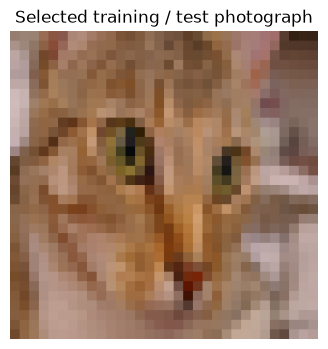

In [3]:
SAMPLES = {
    'sample_cat': data.chelsea(),
    'sample_coffee': data.coffee(),
    'sample_astronaut': data.astronaut(),
    'sample_rocket': data.rocket(),
}

def make_rgb(photo, size):
    if isinstance(photo, np.ndarray):
        photo = Image.fromarray(np.uint8(photo))
    photo = ImageOps.exif_transpose(photo).convert('RGB')
    return photo.resize((size, size), Image.Resampling.LANCZOS)

if IMAGE_SOURCE == 'upload_photo':
    try:
        from google.colab import files
    except ImportError as e:
        raise RuntimeError('Upload through the Google Colab environment, or use a sample image.') from e
    uploaded = files.upload()
    if not uploaded:
        raise RuntimeError('No image selected; upload a JPG/PNG or switch IMAGE_SOURCE to sample_cat.')
    from io import BytesIO
    fname = next(iter(uploaded))
    photo = make_rgb(Image.open(BytesIO(uploaded[fname])), IMAGE_SIZE)
else:
    if IMAGE_SOURCE not in SAMPLES:
        raise ValueError(f'Unknown IMAGE_SOURCE={IMAGE_SOURCE!r}. Choose {list(SAMPLES)} or upload_photo.')
    photo = make_rgb(SAMPLES[IMAGE_SOURCE], IMAGE_SIZE)

selected_rgb = np.asarray(photo, dtype=np.float32) / 255.0
print('Image RGB tensor:', selected_rgb.shape, '| value range:', (selected_rgb.min(), selected_rgb.max()))
plt.figure(figsize=(4,4)); plt.imshow(photo.resize((256,256),Image.Resampling.NEAREST)); plt.title('Selected training / test photograph'); plt.axis('off'); plt.show()

## 4. Optional dataset and tensor flow
One image by itself allows the network to **memorize** that image. `sample_collection` trains on four very different sample photos. A small FCNN may reconstruct its training images but **generalize poorly** to an unseen photograph. This is a feature of the lesson, not a software failure.

Tensor convention: batch of RGB images `(B,H,W,3)` → flatten `(B,H×W×3)`. Values are normalized to `[0,1]`. **No pooling** is used in the basic architecture: explain that optional average pooling would reduce resolution and change the number of input neurons.

In [4]:
if TRAIN_MODE == 'selected_image':
    train_images = selected_rgb[None, ...]
elif TRAIN_MODE == 'sample_collection':
    train_images = np.stack([np.asarray(make_rgb(arr, IMAGE_SIZE), dtype=np.float32)/255.0
                             for arr in SAMPLES.values()])
else:
    raise ValueError('TRAIN_MODE must be selected_image or sample_collection')

clean_train = torch.tensor(train_images, dtype=torch.float32, device=DEVICE).flatten(start_dim=1)
clean_test = torch.tensor(selected_rgb, dtype=torch.float32, device=DEVICE).reshape(1,-1)
INPUT_DIM = IMAGE_SIZE*IMAGE_SIZE*3
print('RGB training images :', train_images.shape)
print('Flattened train tensor:', tuple(clean_train.shape))
print('Input vector length  :', INPUT_DIM)
print('Each batch row corresponds to one RGB image')

RGB training images : (1, 32, 32, 3)
Flattened train tensor: (1, 3072)
Input vector length  : 3072
Each batch row corresponds to one RGB image


## 5. FCNN-AE architecture — **weights and biases are learned**

| Operation | Tensor shape (batch B) | Parameters |
|---|---|---|
| Flatten image | `(B,H,W,3) → (B,D)` | none |
| Encoder dense 1 + activation | `(B,D) → (B,H)` | `D×H + H` |
| Encoder dense 2 **latent** | `(B,H) → (B,Z)` | `H×Z + Z` |
| Decoder dense 1 + activation | `(B,Z) → (B,H)` | `Z×H + H` |
| Decoder dense 2 + sigmoid | `(B,H) → (B,D)` | `H×D + D` |
| Reshape | `(B,D) → (B,H,W,3)` | none |

`D=3×IMAGE_SIZE²`, `H=HIDDEN_NEURONS`, `Z=LATENT_NEURONS`. The final **sigmoid** restricts predictions to `[0,1]`. Here latent features are **deterministic**, unlike a VAE's sampled latent variable.

In [5]:
def activation(name):
    return {'relu':nn.ReLU, 'tanh':nn.Tanh, 'sigmoid':nn.Sigmoid}[name]()

class FCNNAutoencoder(nn.Module):
    def __init__(self, input_dim, hidden, latent, activation_name='relu'):
        super().__init__()
        self.enc1 = nn.Linear(input_dim, hidden)
        self.enc_act = activation(activation_name)
        self.enc2 = nn.Linear(hidden, latent)
        self.dec1 = nn.Linear(latent, hidden)
        self.dec_act = activation(activation_name)
        self.dec2 = nn.Linear(hidden, input_dim)
        self.out_act = nn.Sigmoid()

    def forward(self, x, return_intermediates=False):
        x_flat = x.flatten(start_dim=1)
        h_enc = self.enc_act(self.enc1(x_flat))
        z = self.enc2(h_enc)             # compressed representation
        h_dec = self.dec_act(self.dec1(z))
        y = self.out_act(self.dec2(h_dec))
        if return_intermediates:
            return y, {'flatten':x_flat, 'encoder_hidden':h_enc, 'latent':z,
                       'decoder_hidden':h_dec, 'predicted_pixels':y}
        return y

model = FCNNAutoencoder(INPUT_DIM,HIDDEN_NEURONS,LATENT_NEURONS,ACTIVATION).to(DEVICE)
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
parameter_count = sum(p.numel() for p in model.parameters())
print(model)
print(f'\nArchitecture: {INPUT_DIM} → {HIDDEN_NEURONS} → {LATENT_NEURONS} → {HIDDEN_NEURONS} → {INPUT_DIM}')
print(f'Trainable parameters: {parameter_count:,}')
for name,p in model.named_parameters(): print(f'  {name:16s} {tuple(p.shape)} : {p.numel():,}')

FCNNAutoencoder(
  (enc1): Linear(in_features=3072, out_features=128, bias=True)
  (enc_act): ReLU()
  (enc2): Linear(in_features=128, out_features=16, bias=True)
  (dec1): Linear(in_features=16, out_features=128, bias=True)
  (dec_act): ReLU()
  (dec2): Linear(in_features=128, out_features=3072, bias=True)
  (out_act): Sigmoid()
)

Architecture: 3072 → 128 → 16 → 128 → 3072
Trainable parameters: 793,872
  enc1.weight      (128, 3072) : 393,216
  enc1.bias        (128,) : 128
  enc2.weight      (16, 128) : 2,048
  enc2.bias        (16,) : 16
  dec1.weight      (128, 16) : 2,048
  dec1.bias        (128,) : 128
  dec2.weight      (3072, 128) : 393,216
  dec2.bias        (3072,) : 3,072


## 6. Train from random weights — forward pass, loss, backprop, optimizer

Every epoch: **(i)** prepare input, **(ii)** encoder→latent→decoder, **(iii)** compare predicted and clean RGB using `MSE`, **(iv)** `loss.backward()` calculates gradients via chain rule, **(v)** `optimizer.step()` changes *both encoder and decoder* weights and biases.

`DENOISING_TRAINING=False`: conventional AE reconstructs clean input. `True`: a **denoising FCNN-AE**, trained on randomly masked/noisy pixel blocks and supervised by the original clean image. This differs from pretrained MAE: the FCNN has neither ViT attention nor visible-token selection.

BEFORE training:
Epoch    1/180  |  MSE=0.027021
Epoch   20/180  |  MSE=0.000759
Epoch   40/180  |  MSE=0.000087
Epoch   60/180  |  MSE=0.000018
Epoch   80/180  |  MSE=0.000005
Epoch  100/180  |  MSE=0.000003
Epoch  120/180  |  MSE=0.000002
Epoch  140/180  |  MSE=0.000001
Epoch  160/180  |  MSE=0.000001
Epoch  180/180  |  MSE=0.000001


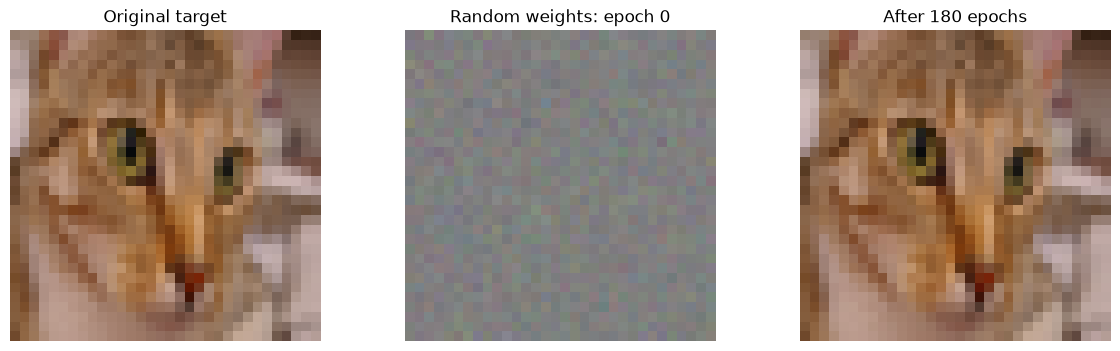

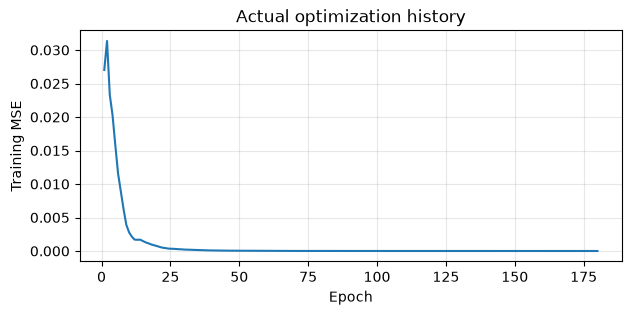

In [6]:
def corruption(x, mask_percent, patch=4):
    # Mask entire small spatial patches, not independent RGB channels.
    # x: (B, 3*S*S) with RGB flatten order H,W,C
    B = x.shape[0]; S = IMAGE_SIZE
    grid = S // patch
    mask = (torch.rand(B,grid,grid,device=x.device) < mask_percent/100).float()
    mask = mask.repeat_interleave(patch,1).repeat_interleave(patch,2)
    out = x.reshape(B,S,S,3)*(1-mask[...,None]) + 0.5*mask[...,None]
    return out.reshape(B,-1)

def train_epochs(n, verbose=True):
    model.train()
    losses=[]
    for ep in range(1,n+1):
        if AUGMENT_TRAINING:
            # Brightness jitter per training image; target = augmented clean image.
            factor = (0.8 + 0.4*torch.rand(clean_train.shape[0],1,device=DEVICE))
            target = (clean_train*factor).clamp(0,1)
        else:
            target = clean_train
        net_input = corruption(target,TRAIN_MASK_PERCENT) if DENOISING_TRAINING else target
        optimizer.zero_grad(set_to_none=True)
        y_pred = model(net_input)
        loss = F.mse_loss(y_pred,target)
        loss.backward()                         # gradients
        optimizer.step()                        # parameter update
        losses.append(float(loss.item()))
        if verbose and (ep==1 or ep%PRINT_EVERY==0 or ep==n):
            print(f'Epoch {ep:4d}/{n}  |  MSE={loss.item():.6f}')
    model.eval()
    return losses

print('BEFORE training:')
with torch.no_grad():
    before_prediction = model(clean_test).cpu().numpy().reshape(IMAGE_SIZE,IMAGE_SIZE,3)

history = train_epochs(EPOCHS)
fig, axes=plt.subplots(1,3,figsize=(12,3.6))
axes[0].imshow(selected_rgb); axes[0].set_title('Original target')
axes[1].imshow(before_prediction); axes[1].set_title('Random weights: epoch 0')
with torch.no_grad():
    after_prediction = model(clean_test).cpu().numpy().reshape(IMAGE_SIZE,IMAGE_SIZE,3)
axes[2].imshow(after_prediction); axes[2].set_title(f'After {EPOCHS} epochs')
for ax in axes: ax.axis('off')
plt.tight_layout();plt.show()
plt.figure(figsize=(7,3));plt.plot(np.arange(1,EPOCHS+1),history);plt.xlabel('Epoch');plt.ylabel('Training MSE');plt.title('Actual optimization history');plt.grid(alpha=.3);plt.show()

## 7. Inspect intermediate **tensors**, activations, weights, biases and latent vectors
Use this to connect the notebook to the earlier **AE dashboard**. The latent vector does not have predefined semantics (e.g., "one neuron = eye"). Its meaning emerges through joint training.

flatten              shape=(1, 3072)       range=[+0.0000, +0.8118]
encoder_hidden       shape=(1, 128)        range=[+0.0000, +10.2616]
latent               shape=(1, 16)         range=[-2.6824, +2.5419]
decoder_hidden       shape=(1, 128)        range=[+0.0000, +1.3832]
predicted_pixels     shape=(1, 3072)       range=[+0.0246, +0.8118]


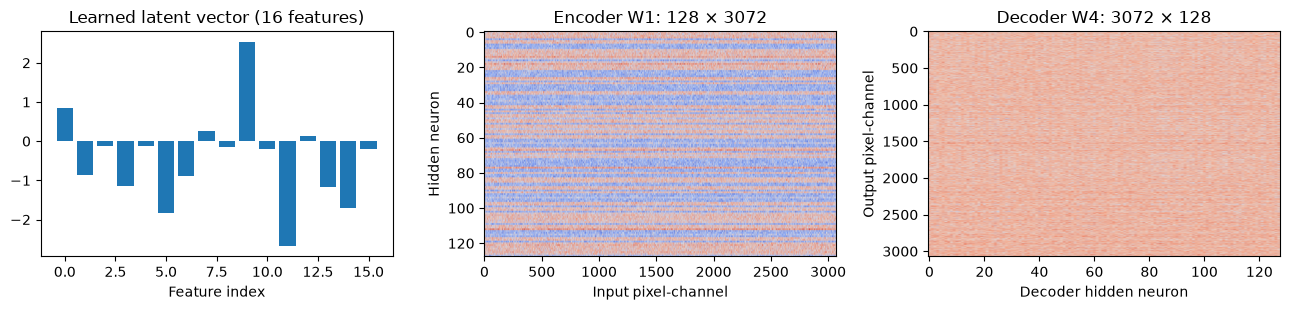

One neuron example (first encoder hidden neuron):
 weighted sum = -0.10073 | after relu = 0.0


In [7]:
with torch.no_grad():
    output, tensors = model(clean_test,return_intermediates=True)
for name,t in tensors.items():
    vals=t.detach().cpu().numpy()
    print(f'{name:20s} shape={str(tuple(t.shape)):15s} range=[{vals.min():+.4f}, {vals.max():+.4f}]')

fig,axes=plt.subplots(1,3,figsize=(13,3.2))
latent=tensors['latent'][0].cpu().numpy()
axes[0].bar(np.arange(len(latent)),latent);axes[0].set_title(f'Learned latent vector ({len(latent)} features)'); axes[0].set_xlabel('Feature index')
w=model.enc1.weight.detach().cpu().numpy()
axes[1].imshow(w,aspect='auto',cmap='coolwarm');axes[1].set_title(f'Encoder W1: {w.shape[0]} × {w.shape[1]}');axes[1].set_xlabel('Input pixel-channel');axes[1].set_ylabel('Hidden neuron')
w4=model.dec2.weight.detach().cpu().numpy()
axes[2].imshow(w4,aspect='auto',cmap='coolwarm');axes[2].set_title(f'Decoder W4: {w4.shape[0]} × {w4.shape[1]}');axes[2].set_xlabel('Decoder hidden neuron');axes[2].set_ylabel('Output pixel-channel')
plt.tight_layout();plt.show()
print('One neuron example (first encoder hidden neuron):')
with torch.no_grad():
    weighted_sum = torch.dot(clean_test[0],model.enc1.weight[0]) + model.enc1.bias[0]
    activated = model.enc_act(weighted_sum)
print(' weighted sum =',round(weighted_sum.item(),5),'| after',ACTIVATION,'=',round(activated.item(),5))

## 8. Interactive experiments: vary **mask percent and seed**
This section applies *new masking at test time*. If you have trained a standard AE (`DENOISING_TRAINING=False`), its performance on masked inputs is generally poor because it was **never trained to remove masks**. To teach denoising fairly, set `DENOISING_TRAINING=True` in Section 2, rerun Sections 5–6, then use this experiment.

**Three views:** original → masked input → decoder output (all pixels predicted). There is also a **composite** that copies visible pixels and replaces only hidden regions with predictions, making it visually comparable to Lab 11A.

Scores: Hidden MSE/PSNR are computed on **masked pixels**. Composite SSIM is computed on the **whole** completed picture; it can look optimistic when the unmasked region is copied. Not classification accuracy.

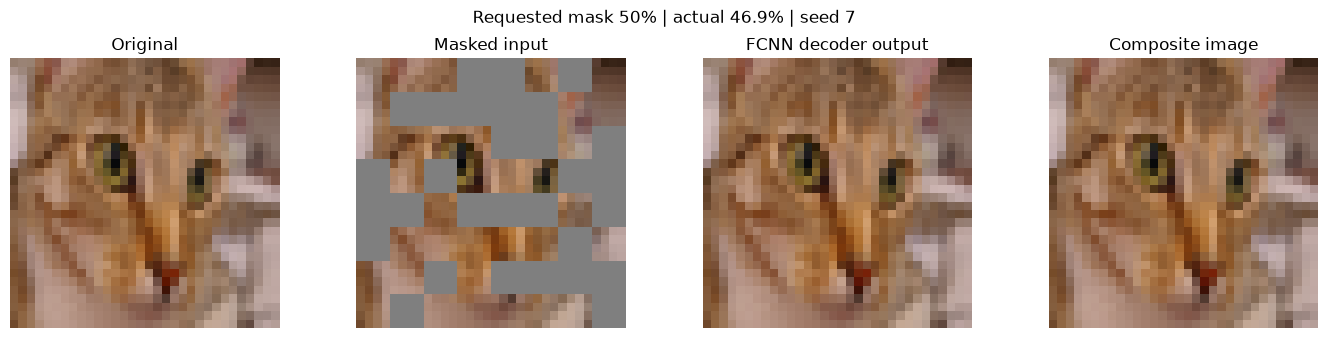

hidden_mse: 2.2901e-05 | hidden_mae: 0.0040514 | hidden_psnr: 46.401 | composite_mse: 1.0735e-05 | composite_psnr: 49.692 | composite_ssim: 0.99959


interactive(children=(IntSlider(value=50, description='Mask %', max=95, min=5, step=5), IntSlider(value=7, des…

In [8]:
def calculate_stats(original, predicted, mask, composite):
    # Images are RGB floats in [0,1]; mask is 2D Boolean array
    if mask.any():
        err = original[mask]-predicted[mask]
        hidden_mse = float(np.mean(err**2)); hidden_mae=float(np.mean(abs(err)))
        hidden_psnr=float(-10*np.log10(max(hidden_mse,1e-12)))
    else:
        hidden_mse=hidden_mae=hidden_psnr=float('nan')
    whole_mse=float(np.mean((original-composite)**2))
    whole_psnr=float(-10*np.log10(max(whole_mse,1e-12)))
    composite_ssim=float(structural_similarity(original,composite,data_range=1.0,channel_axis=2,win_size=7))
    return dict(hidden_mse=hidden_mse,hidden_mae=hidden_mae,hidden_psnr=hidden_psnr,
                composite_mse=whole_mse,composite_psnr=whole_psnr,composite_ssim=composite_ssim)

def reconstruct_with_mask(mask_percent=50,seed=7,show=True,save=False):
    rng=np.random.default_rng(seed); S=IMAGE_SIZE; block=4; G=S//block
    blockmask=(rng.random((G,G)) < mask_percent/100)
    mask=np.repeat(np.repeat(blockmask,block,axis=0),block,axis=1)
    masked=selected_rgb.copy();masked[mask]=0.5
    model.eval()
    with torch.no_grad():
        prediction=model(torch.tensor(masked.reshape(1,-1),dtype=torch.float32,device=DEVICE)).cpu().numpy().reshape(S,S,3)
    composite=selected_rgb.copy();composite[mask]=prediction[mask]
    stats=calculate_stats(selected_rgb,prediction,mask,composite)
    if show:
        fig,axes=plt.subplots(1,4,figsize=(14,3.4))
        views=[selected_rgb,masked,prediction,composite]
        labels=['Original','Masked input','FCNN decoder output','Composite image']
        for ax,v,label in zip(axes,views,labels):
            ax.imshow(v,interpolation='nearest');ax.set_title(label);ax.axis('off')
        plt.suptitle(f'Requested mask {mask_percent}% | actual {mask.mean()*100:.1f}% | seed {seed}')
        plt.tight_layout();plt.show()
        print(' | '.join(f'{k}: {v:.5g}' for k,v in stats.items()))
    if save:
        Image.fromarray(np.uint8(np.clip(composite,0,1)*255)).save(OUTDIR / f'composite_mask{mask_percent}_seed{seed}.png')
    return stats

reconstruct_with_mask(50,seed=7,save=True)

# Widgets will render in Colab; no separate button is required.
import ipywidgets as widgets
from ipywidgets import interact
try:
    from google.colab import output
    output.enable_custom_widget_manager()
except ImportError:
    pass
@interact(mask_percent=widgets.IntSlider(value=50,min=5,max=95,step=5,description='Mask %'),
          seed=widgets.IntSlider(value=7,min=0,max=100,step=1,description='Seed'))
def explore(mask_percent,seed):
    reconstruct_with_mask(mask_percent,seed,show=True,save=False)

## 9. Quantitative comparison: different mask percentages, fixed seed
Compare **hidden PSNR** and **composite SSIM**. The former reports accuracy on generated regions; the latter measures overall appearance with unchanged visible pixels.

  Mask   Hidden MSE   Hidden PSNR   Composite SSIM
   25%      0.00001         50.96            1.000
   50%      0.00002         46.40            1.000
   75%      0.00005         42.61            0.999
   90%      0.00011         39.56            0.998


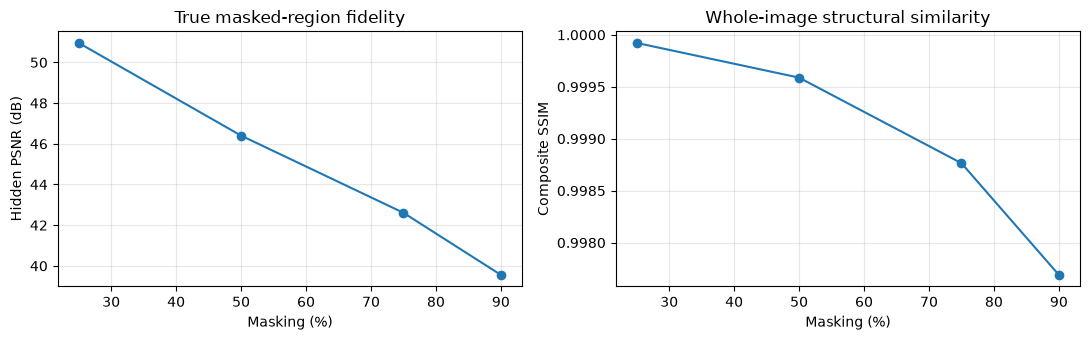

Saved comparison CSV and composite images to: /private/tmp/claude-502/-Users-Suyash-Desktop-Quizerr/1600d1fe-cca2-4349-9b91-4e34faa1e390/scratchpad/run/lab11b_fcnn_outputs


In [9]:
MASK_LEVELS=[25,50,75,90]   # <- STUDENT: edit this list
COMPARISON_SEED=7          # <- STUDENT: choose the same seed for a controlled comparison
results=[]
for m in MASK_LEVELS:
    item={'mask_percent':m,**reconstruct_with_mask(m,COMPARISON_SEED,show=False,save=True)}
    results.append(item)
print(f'{"Mask":>6} {"Hidden MSE":>12} {"Hidden PSNR":>13} {"Composite SSIM":>16}')
for v in results:
    print(f'{v["mask_percent"]:5d}% {v["hidden_mse"]:12.5f} {v["hidden_psnr"]:13.2f} {v["composite_ssim"]:16.3f}')
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot([v['mask_percent'] for v in results],[v['hidden_psnr'] for v in results],'-o')
axes[0].set(xlabel='Masking (%)',ylabel='Hidden PSNR (dB)',title='True masked-region fidelity')
axes[1].plot([v['mask_percent'] for v in results],[v['composite_ssim'] for v in results],'-o')
axes[1].set(xlabel='Masking (%)',ylabel='Composite SSIM',title='Whole-image structural similarity')
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout();plt.show()
import csv
with open(OUTDIR/'masking_comparison.csv','w',newline='') as f:
    writer=csv.DictWriter(f,fieldnames=list(results[0]));writer.writeheader();writer.writerows(results)
print('Saved comparison CSV and composite images to:',OUTDIR.resolve())

## 10. Further epoch experiment — continue training **same model**
Running this cell **adds** another 100 epochs without resetting weights. Editing architecture controls in Section 2 requires rerunning Section 5 to create a fresh network, then Section 6 to train it. If you want another completely fresh trial, rerun Section 5 first.

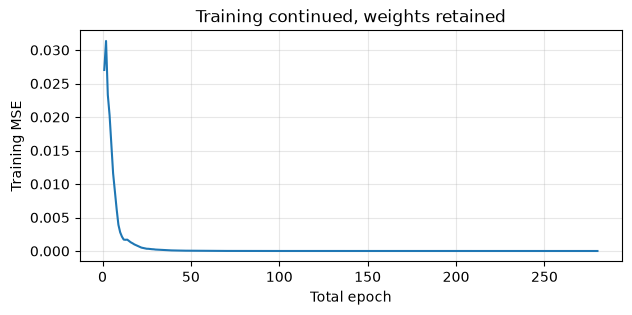

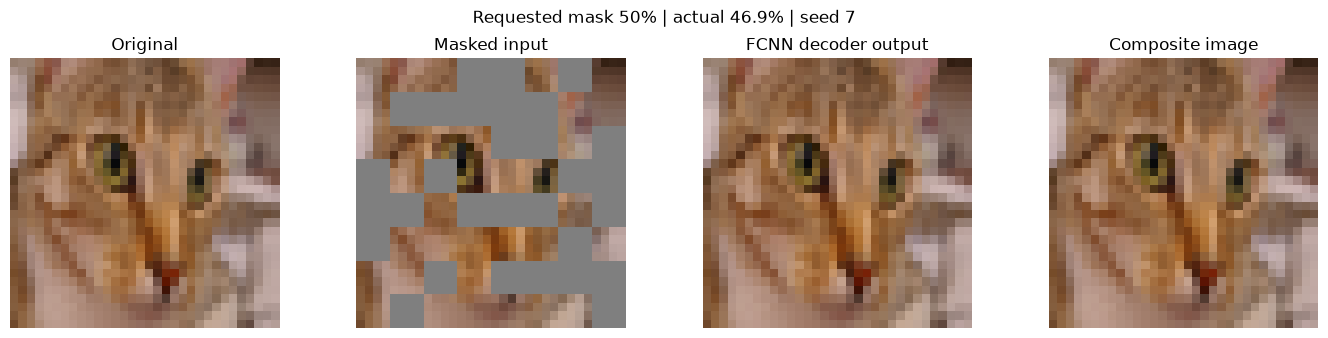

hidden_mse: 2.2576e-05 | hidden_mae: 0.0040321 | hidden_psnr: 46.464 | composite_mse: 1.0582e-05 | composite_psnr: 49.754 | composite_ssim: 0.9996


{'hidden_mse': 2.257560299767647e-05,
 'hidden_mae': 0.004032109398394823,
 'hidden_psnr': 46.463606407900464,
 'composite_mse': 1.0582313734630588e-05,
 'composite_psnr': 49.754193670527734,
 'composite_ssim': 0.9995951652526855}

In [10]:
MORE_EPOCHS=100   # <- STUDENT: change to 20, 100, 300
more_history=train_epochs(MORE_EPOCHS,verbose=False)
plt.figure(figsize=(7,3));plt.plot(np.arange(1,len(history)+len(more_history)+1),history+more_history)
plt.xlabel('Total epoch');plt.ylabel('Training MSE');plt.title('Training continued, weights retained');plt.grid(alpha=.3);plt.show()
reconstruct_with_mask(50,seed=7,show=True)

## 11. Optional: what does **pooling** do? (standalone comparison)
A 2×2 **average pool** compresses the image spatially **before flattening**: `32×32×3 → 16×16×3`, i.e. `3072 → 768` values. These 768 are **pooled RGB values**, not ViT embeddings. To actually train on pooled images you would need to set `IMAGE_SIZE=16` in Section 2 and rerun subsequent cells; this standalone cell only illustrates pooling.

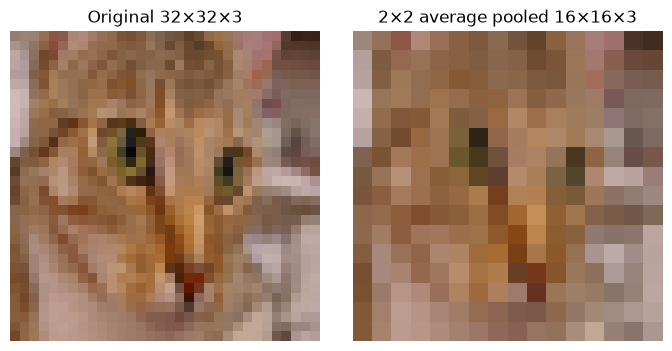

Before pooling: (1, 3, 32, 32) → after: (1, 3, 16, 16)
Flatten values: 3072 → 768


In [11]:
# Pooling illustration in HWC → NCHW tensor order
src=torch.from_numpy(selected_rgb.copy()).permute(2,0,1).unsqueeze(0)
pooled=F.avg_pool2d(src,kernel_size=2,stride=2)
pool_img=pooled[0].permute(1,2,0).numpy()
fig,axes=plt.subplots(1,2,figsize=(7,3.5))
axes[0].imshow(selected_rgb,interpolation='nearest');axes[0].set_title(f'Original {IMAGE_SIZE}×{IMAGE_SIZE}×3')
axes[1].imshow(pool_img,interpolation='nearest');axes[1].set_title(f'2×2 average pooled {IMAGE_SIZE//2}×{IMAGE_SIZE//2}×3')
for a in axes:a.axis('off')
plt.tight_layout();plt.show()
print('Before pooling:',tuple(src.shape),'→ after:',tuple(pooled.shape))
print('Flatten values:',src.numel(),'→',pooled.numel())

---
# Completed experiments (support for the viva questions in Section 12)
The experiments below build **their own** networks (fixed seeds, fresh random weights), so the model from Sections 5–10 is untouched. Section 2's controls (`IMAGE_SIZE`, `LEARNING_RATE`, …) are reused as defaults.

| Experiment | Viva question |
|---|---|
| A. Shapes and parameter counts, 16×16 vs 32×32 | Q1, Q2 |
| B. Decoded picture at epoch 0 / 1 / 20 / 100 / 300; what backprop changes | Q3 |
| C. Latent size 2…64 (one image **and** a many-image dataset) | Q4 |
| D. `relu` vs `tanh` vs `sigmoid` from identical initial weights | Q5 |
| E. Ordinary AE vs **denoising** AE under masking, hidden vs composite scores | Q6, Q7 |
| F. Generalisation: train on 3 photographs, test on an unseen one | Q8 |

In [12]:
# ---------- Reusable helpers for Experiments A-F ----------
def psnr_from_mse(mse):
    return float(-10 * np.log10(max(mse, 1e-12)))

def fresh_model(size, hidden, latent, act, seed):
    """New network with random weights drawn from a fixed seed (identical start for fair comparisons)."""
    torch.manual_seed(seed)
    return FCNNAutoencoder(3 * size * size, hidden, latent, act).to(DEVICE)

def random_block_mask(x, pct, size, patch=4):
    """Hide random 4x4 blocks (grey 0.5) in a batch of flattened HWC images."""
    B = x.shape[0]; g = size // patch
    m = (torch.rand(B, g, g, device=x.device) < pct / 100).float()
    m = m.repeat_interleave(patch, 1).repeat_interleave(patch, 2)
    return (x.reshape(B, size, size, 3) * (1 - m[..., None]) + 0.5 * m[..., None]).reshape(B, -1)

def fit(m, x, epochs, size, lr=LEARNING_RATE, denoise_pct=0, snapshots=(), probe=None, seed=0):
    """Full-batch Adam on MSE. Returns (loss history, {epoch: probe reconstruction})."""
    opt = torch.optim.Adam(m.parameters(), lr=lr)
    torch.manual_seed(10_000 + seed)
    losses, snaps = [], {}
    def snap(ep):
        m.eval()
        with torch.no_grad():
            snaps[ep] = m(probe).cpu().numpy().reshape(size, size, 3)
        m.train()
    if 0 in snapshots: snap(0)
    m.train()
    for ep in range(1, epochs + 1):
        inp = random_block_mask(x, denoise_pct, size) if denoise_pct > 0 else x
        opt.zero_grad(set_to_none=True)
        loss = F.mse_loss(m(inp), x)
        loss.backward()
        opt.step()
        losses.append(loss.item())
        if ep in snapshots: snap(ep)
    m.eval()
    return losses, snaps

@torch.no_grad()
def reconstruct(m, x, size):
    m.eval()
    return m(x).cpu().numpy().reshape(-1, size, size, 3)

def quality(target, pred):
    mse = float(np.mean((target - pred) ** 2))
    ssim = float(structural_similarity(target, pred, data_range=1.0, channel_axis=2, win_size=7))
    return dict(mse=mse, psnr=psnr_from_mse(mse), ssim=ssim)

def to_tensor(arr):
    return torch.tensor(np.asarray(arr, dtype=np.float32), device=DEVICE).reshape(len(arr), -1)

import csv
def save_csv(name, rows):
    with open(OUTDIR / name, 'w', newline='') as f:
        w = csv.DictWriter(f, fieldnames=list(rows[0])); w.writeheader(); w.writerows(rows)
print('Helpers ready. Device:', DEVICE)

Helpers ready. Device: cpu


## Experiment A — shapes and parameter counts (Q1, Q2)
A `16×16×3` image has `16·16·3 = 768` scalar values; the flatten layer simply lays them in one row, so the first dense layer has 768 inputs. We compute the matrix shapes and the number of weights/biases from the formula `D→H→Z→H→D` and **verify the formula against PyTorch's own count**.

In [13]:
H_A, Z_A = 128, 16
summary_A = []
for size in (16, 32):
    D = 3 * size * size
    layers = [('Encoder dense 1', D, H_A), ('Encoder dense 2 (latent)', H_A, Z_A),
              ('Decoder dense 1', Z_A, H_A), ('Decoder dense 2 (+sigmoid)', H_A, D)]
    print(f'\n=== IMAGE_SIZE={size}:  {size}x{size}x3 = {D} inputs   |   {D} -> {H_A} -> {Z_A} -> {H_A} -> {D}')
    print(f'{"Layer":28s}{"W shape (out,in)":>20s}{"weights":>10s}{"biases":>8s}{"total":>10s}')
    total = 0
    for name, i, o in layers:
        print(f'{name:28s}{str((o, i)):>20s}{i*o:10,d}{o:8,d}{i*o+o:10,d}'); total += i * o + o
    actual = sum(p.numel() for p in fresh_model(size, H_A, Z_A, 'relu', 0).parameters())
    assert total == actual, (total, actual)
    print(f'{"TOTAL (formula)":28s}{"":>20s}{"":>10s}{"":>8s}{total:10,d}   == PyTorch count {actual:,d}  OK')
    summary_A.append(dict(image_size=size, input_dim=D, hidden=H_A, latent=Z_A, parameters=total))
r16, r32 = summary_A
print(f'\nGoing from 16x16 to 32x32 multiplies inputs by {r32["input_dim"]/r16["input_dim"]:.0f}x and parameters by {r32["parameters"]/r16["parameters"]:.2f}x '
      f'(only the two layers that touch the pixel vector grow).')
save_csv('experiment_A_parameters.csv', summary_A)


=== IMAGE_SIZE=16:  16x16x3 = 768 inputs   |   768 -> 128 -> 16 -> 128 -> 768
Layer                           W shape (out,in)   weights  biases     total
Encoder dense 1                       (128, 768)    98,304     128    98,432
Encoder dense 2 (latent)               (16, 128)     2,048      16     2,064
Decoder dense 1                        (128, 16)     2,048     128     2,176
Decoder dense 2 (+sigmoid)            (768, 128)    98,304     768    99,072
TOTAL (formula)                                                      201,744   == PyTorch count 201,744  OK

=== IMAGE_SIZE=32:  32x32x3 = 3072 inputs   |   3072 -> 128 -> 16 -> 128 -> 3072
Layer                           W shape (out,in)   weights  biases     total
Encoder dense 1                      (128, 3072)   393,216     128   393,344
Encoder dense 2 (latent)               (16, 128)     2,048      16     2,064
Decoder dense 1                        (128, 16)     2,048     128     2,176
Decoder dense 2 (+sigmoid)           (

## Experiment B — decoded picture vs. number of epochs (Q3)
One fresh network (seed 17, default controls) is trained for 300 epochs on the selected image while the decoded picture is recorded at epoch 0 (random weights), 1, 20, 100 and 300. Afterwards we compare every tensor with its initial value to show **what back-propagation changes** (weights and biases) and **what it does not** (architecture, activation, learning rate, the data).

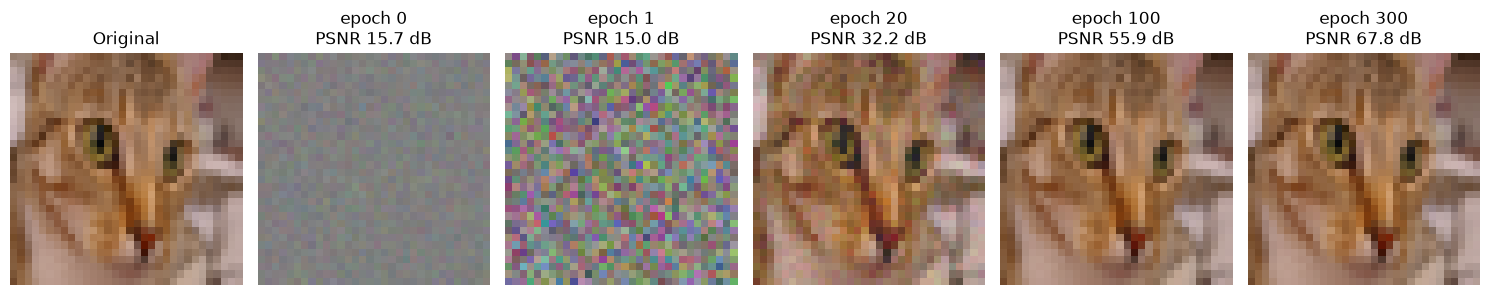

 epoch        MSE   PSNR dB    SSIM
     0   2.70e-02     15.68   0.104
     1   3.13e-02     15.04   0.164
    20   6.09e-04     32.15   0.966
   100   2.54e-06     55.95   1.000
   300   1.65e-07     67.81   1.000


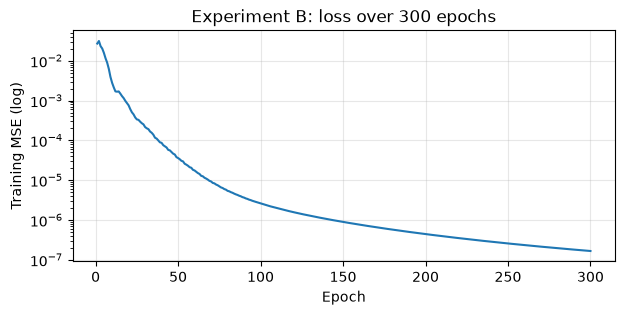


What did back-propagation change?
  enc1.weight  shape (128, 3072)  mean |change| = 0.00835
  enc1.bias    shape (128,)       mean |change| = 0.00839
  enc2.weight  shape (16, 128)    mean |change| = 0.00931
  enc2.bias    shape (16,)        mean |change| = 0.00738
  dec1.weight  shape (128, 16)    mean |change| = 0.01343
  dec1.bias    shape (128,)       mean |change| = 0.01365
  dec2.weight  shape (3072, 128)  mean |change| = 0.01583
  dec2.bias    shape (3072,)      mean |change| = 0.02874

UNCHANGED by training: architecture/shapes -> True | activation -> ReLU | learning rate -> 0.003 | training image -> fixed target


In [14]:
SNAPS = (0, 1, 20, 100, 300)
net_B = fresh_model(IMAGE_SIZE, HIDDEN_NEURONS, LATENT_NEURONS, ACTIVATION, SEED)
init_state = {k: v.detach().clone() for k, v in net_B.state_dict().items()}
init_arch = [(k, tuple(v.shape)) for k, v in net_B.state_dict().items()]
loss_B, snaps_B = fit(net_B, clean_test, 300, IMAGE_SIZE, LEARNING_RATE, snapshots=SNAPS, probe=clean_test, seed=SEED)

fig, axes = plt.subplots(1, len(SNAPS) + 1, figsize=(15, 3.3))
axes[0].imshow(selected_rgb, interpolation='nearest'); axes[0].set_title('Original'); axes[0].axis('off')
rows_B = []
for ax, ep in zip(axes[1:], SNAPS):
    q = quality(selected_rgb, snaps_B[ep]); rows_B.append(dict(epoch=ep, **q))
    ax.imshow(np.clip(snaps_B[ep], 0, 1), interpolation='nearest')
    ax.set_title(f'epoch {ep}\nPSNR {q["psnr"]:.1f} dB'); ax.axis('off')
plt.tight_layout(); plt.show()
print(f'{"epoch":>6} {"MSE":>10} {"PSNR dB":>9} {"SSIM":>7}')
for r in rows_B: print(f'{r["epoch"]:6d} {r["mse"]:10.2e} {r["psnr"]:9.2f} {r["ssim"]:7.3f}')
save_csv('experiment_B_epochs.csv', rows_B)

plt.figure(figsize=(7, 3)); plt.semilogy(np.arange(1, 301), loss_B); plt.xlabel('Epoch'); plt.ylabel('Training MSE (log)')
plt.title('Experiment B: loss over 300 epochs'); plt.grid(alpha=.3); plt.show()

print('\nWhat did back-propagation change?')
for (k, shp) in init_arch:
    delta = (net_B.state_dict()[k] - init_state[k]).abs().mean().item()
    print(f'  {k:12s} shape {str(shp):12s} mean |change| = {delta:.5f}')
same_arch = init_arch == [(k, tuple(v.shape)) for k, v in net_B.state_dict().items()]
print('\nUNCHANGED by training: architecture/shapes ->', same_arch,
      '| activation ->', type(net_B.enc_act).__name__, '| learning rate ->', LEARNING_RATE,
      '| training image -> fixed target')

## Experiment C — latent dimension 2, 4, 8, 16, 32, 64 (Q4)
Same architecture and training for each size (`relu`, 128 hidden units, learning rate from Section 2, 3 random initialisations; mean ± std shown).

* **C1 – one image.** The training set is a single picture, so the decoder only has to output *one* fixed answer.
* **C2 – many images.** 200 different 32×32 crops of the four sample photographs (160 train / 40 held-out). Now the latent vector has to carry information that tells the images apart, so its size should matter.

Held-out crops of C2 come from the same four photographs, so their scores are optimistic compared with a really unseen photograph (that harder test is Experiment F).

C2 dataset: (200, 32, 32, 3) -> train 160 | held-out 40



   Z |    C1 one-image PSNR |    C2 train PSNR |   C2 held-out PSNR
   2 |        63.42 +/- 1.07 |     18.63 +/- 0.38 |       17.21 +/- 0.19
   4 |        63.79 +/- 1.97 |     21.44 +/- 2.51 |       17.32 +/- 0.24
   8 |        65.82 +/- 0.29 |     22.56 +/- 0.79 |       17.36 +/- 0.11
  16 |        65.41 +/- 2.52 |     24.45 +/- 1.03 |       17.52 +/- 0.05
  32 |        66.55 +/- 1.53 |     26.24 +/- 0.20 |       17.68 +/- 0.06
  64 |        63.77 +/- 3.87 |     27.27 +/- 0.29 |       18.04 +/- 0.10


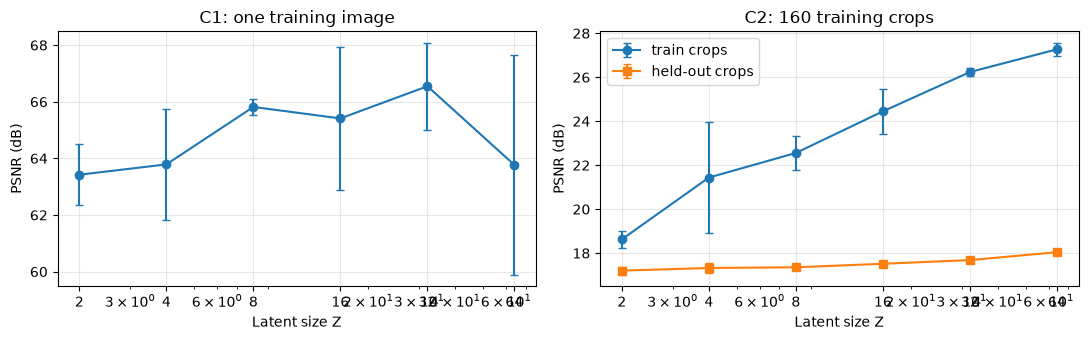

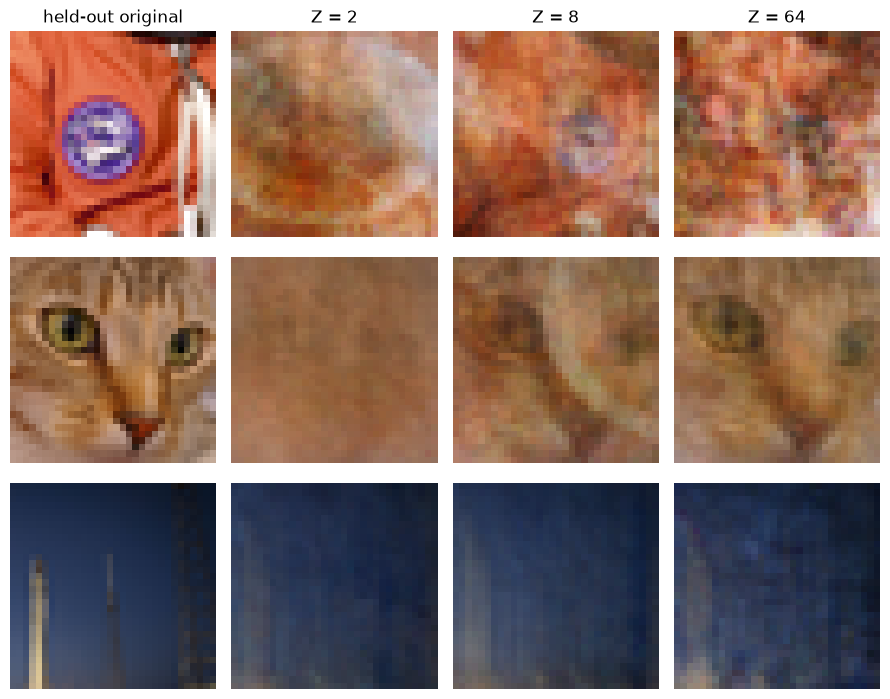

In [15]:
LATENTS = [2, 4, 8, 16, 32, 64]
SEEDS3 = [0, 1, 2]

# ---- C1: single image ----
rows_C1 = []
for Z in LATENTS:
    qs = []
    for s in SEEDS3:
        m = fresh_model(IMAGE_SIZE, 128, Z, 'relu', 100 + s)
        fit(m, clean_test, 300, IMAGE_SIZE, seed=s)
        qs.append(quality(selected_rgb, reconstruct(m, clean_test, IMAGE_SIZE)[0]))
    rows_C1.append(dict(latent=Z, psnr_mean=np.mean([q['psnr'] for q in qs]), psnr_std=np.std([q['psnr'] for q in qs]),
                        ssim_mean=np.mean([q['ssim'] for q in qs])))

# ---- C2: many-image dataset (crops of the 4 sample photographs) ----
def make_patches(n_per_image=50, size=IMAGE_SIZE, seed=0):
    rng = np.random.default_rng(seed); out = []
    for arr in SAMPLES.values():
        Hh, Ww, _ = arr.shape
        for _ in range(n_per_image):
            side = int(rng.integers(64, min(Hh, Ww) + 1))
            y0 = int(rng.integers(0, Hh - side + 1)); x0 = int(rng.integers(0, Ww - side + 1))
            out.append(np.asarray(make_rgb(arr[y0:y0 + side, x0:x0 + side], size), dtype=np.float32) / 255.0)
    return np.stack(out)
patches = make_patches()
perm = np.random.default_rng(1).permutation(len(patches))
tr_p, te_p = patches[perm[:160]], patches[perm[160:]]
Xtr_p, Xte_p = to_tensor(tr_p), to_tensor(te_p)
print('C2 dataset:', patches.shape, '-> train', tr_p.shape[0], '| held-out', te_p.shape[0])

def mean_psnr(m, X, imgs):
    pred = reconstruct(m, X, IMAGE_SIZE)
    return float(np.mean([quality(a, b)['psnr'] for a, b in zip(imgs, pred)]))

rows_C2, example_models = [], {}
for Z in LATENTS:
    tr, te = [], []
    for s in SEEDS3:
        m = fresh_model(IMAGE_SIZE, 128, Z, 'relu', 200 + s)
        fit(m, Xtr_p, 800, IMAGE_SIZE, seed=s)
        tr.append(mean_psnr(m, Xtr_p, tr_p)); te.append(mean_psnr(m, Xte_p, te_p))
        if s == 0: example_models[Z] = m
    rows_C2.append(dict(latent=Z, train_psnr_mean=np.mean(tr), train_psnr_std=np.std(tr),
                        heldout_psnr_mean=np.mean(te), heldout_psnr_std=np.std(te)))

print(f'\n{"Z":>4} | {"C1 one-image PSNR":>20} | {"C2 train PSNR":>16} | {"C2 held-out PSNR":>18}')
for a, b in zip(rows_C1, rows_C2):
    print(f'{a["latent"]:4d} | {a["psnr_mean"]:12.2f} +/- {a["psnr_std"]:4.2f} | {b["train_psnr_mean"]:9.2f} +/- {b["train_psnr_std"]:4.2f} | {b["heldout_psnr_mean"]:11.2f} +/- {b["heldout_psnr_std"]:4.2f}')
save_csv('experiment_C1_latent_single_image.csv', rows_C1); save_csv('experiment_C2_latent_dataset.csv', rows_C2)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].errorbar(LATENTS, [r['psnr_mean'] for r in rows_C1], [r['psnr_std'] for r in rows_C1], fmt='-o', capsize=3)
axes[0].set(xscale='log', xlabel='Latent size Z', ylabel='PSNR (dB)', title='C1: one training image'); axes[0].set_xticks(LATENTS, LATENTS)
axes[1].errorbar(LATENTS, [r['train_psnr_mean'] for r in rows_C2], [r['train_psnr_std'] for r in rows_C2], fmt='-o', capsize=3, label='train crops')
axes[1].errorbar(LATENTS, [r['heldout_psnr_mean'] for r in rows_C2], [r['heldout_psnr_std'] for r in rows_C2], fmt='-s', capsize=3, label='held-out crops')
axes[1].set(xscale='log', xlabel='Latent size Z', ylabel='PSNR (dB)', title='C2: 160 training crops'); axes[1].set_xticks(LATENTS, LATENTS); axes[1].legend()
for ax in axes: ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

# Visual: three held-out crops decoded with Z = 2, 8, 64
show_Z = [2, 8, 64]; pick = [0, 1, 2]
fig, axes = plt.subplots(len(pick), len(show_Z) + 1, figsize=(9, 2.4 * len(pick)))
for r, idx in enumerate(pick):
    axes[r, 0].imshow(te_p[idx], interpolation='nearest'); axes[r, 0].set_title('held-out original' if r == 0 else ''); axes[r, 0].axis('off')
    for c, Z in enumerate(show_Z, start=1):
        pred = reconstruct(example_models[Z], Xte_p[idx:idx + 1], IMAGE_SIZE)[0]
        axes[r, c].imshow(np.clip(pred, 0, 1), interpolation='nearest'); axes[r, c].axis('off')
        if r == 0: axes[r, c].set_title(f'Z = {Z}')
plt.tight_layout(); plt.show()

## Experiment D — `relu` vs `tanh` vs `sigmoid` (Q5)
For a fair comparison the **only** difference between runs must be the activation. Every run therefore starts from newly created weights drawn from the *same seed* (a network that was already trained with one activation would start the next one from an advantage), uses the same data, learning rate and number of epochs, and is repeated with 3 seeds because a single random start can mislead.

 activation  epochs to MSE<1e-3   final MSE        PSNR (dB)    SSIM
       relu                18.0    2.08e-07     66.82 +/- 0.14   1.000
       tanh                16.0    1.88e-07     67.35 +/- 0.90   1.000
    sigmoid                18.3    1.14e-07     69.50 +/- 0.72   1.000


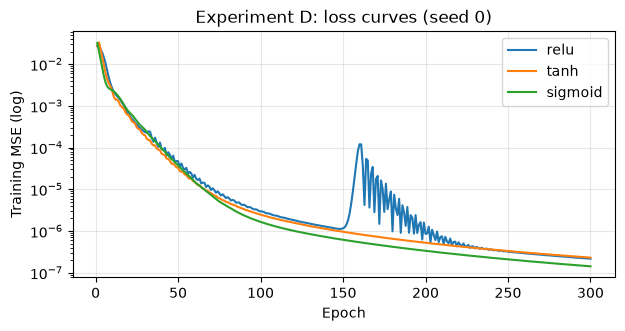

In [16]:
ACTS = ['relu', 'tanh', 'sigmoid']
rows_D, curves_D = [], {}
for a in ACTS:
    qs, hit = [], []
    for s in SEEDS3:
        m = fresh_model(IMAGE_SIZE, 128, 16, a, 300 + s)      # same seed list for every activation
        losses, _ = fit(m, clean_test, 300, IMAGE_SIZE, seed=s)
        hit.append(next((i + 1 for i, l in enumerate(losses) if l < 1e-3), 300))   # epochs until MSE < 1e-3
        qs.append(quality(selected_rgb, reconstruct(m, clean_test, IMAGE_SIZE)[0]))
        if s == 0: curves_D[a] = losses
    rows_D.append(dict(activation=a, epochs_to_mse_1e3=float(np.mean(hit)), final_mse=np.mean([q['mse'] for q in qs]), psnr_mean=np.mean([q['psnr'] for q in qs]),
                       psnr_std=np.std([q['psnr'] for q in qs]), ssim_mean=np.mean([q['ssim'] for q in qs])))
print(f'{"activation":>11} {"epochs to MSE<1e-3":>19} {"final MSE":>11} {"PSNR (dB)":>16} {"SSIM":>7}')
for r in rows_D: print(f'{r["activation"]:>11} {r["epochs_to_mse_1e3"]:19.1f} {r["final_mse"]:11.2e} {r["psnr_mean"]:9.2f} +/- {r["psnr_std"]:4.2f} {r["ssim_mean"]:7.3f}')
save_csv('experiment_D_activations.csv', rows_D)
plt.figure(figsize=(7, 3.2))
for a in ACTS: plt.semilogy(np.arange(1, 301), curves_D[a], label=a)
plt.xlabel('Epoch'); plt.ylabel('Training MSE (log)'); plt.title('Experiment D: loss curves (seed 0)'); plt.legend(); plt.grid(alpha=.3); plt.show()

## Experiment E — ordinary AE vs **denoising** AE under masking (Q6, Q7)
Two fresh networks with identical initial weights, trained for the same 1500 epochs on the same image:
* **ordinary AE** – always sees the complete image,
* **denoising AE** – sees the image with 40 % of its 4×4 blocks hidden (new random blocks every epoch) but is scored against the complete image.

Both are then tested on 20 unseen random masks per mask level (seeds 100–119, not used in training). A grey-fill baseline (`0.5` in hidden blocks, i.e. doing nothing) is added: **hidden PSNR** is computed only where pixels were removed; **composite PSNR/SSIM** use the whole completed picture, where the copied visible pixels are perfect and flatter the result.

This tests completion of the *same* image the network memorised; it is not generalisation (see Experiment F).

Final training MSE  ordinary: 6.70e-09   denoising: 1.55e-06  (denoising must also repair damaged input)

 mask model                   hidden PSNR  composite PSNR  composite SSIM
  25% grey fill (no model)          16.05           22.12           0.754
  25% ordinary AE                   53.52           59.58           1.000
  25% denoising AE                  52.55           58.61           1.000
  50% grey fill (no model)          15.77           18.80           0.531
  50% ordinary AE                   46.27           49.30           0.999
  50% denoising AE                  51.31           54.34           1.000
  75% grey fill (no model)          15.77           17.01           0.334
  75% ordinary AE                   42.12           43.36           0.999
  75% denoising AE                  49.94           51.18           1.000
  90% grey fill (no model)          15.71           16.18           0.184
  90% ordinary AE                   40.18           40.65           0.998
  90% 

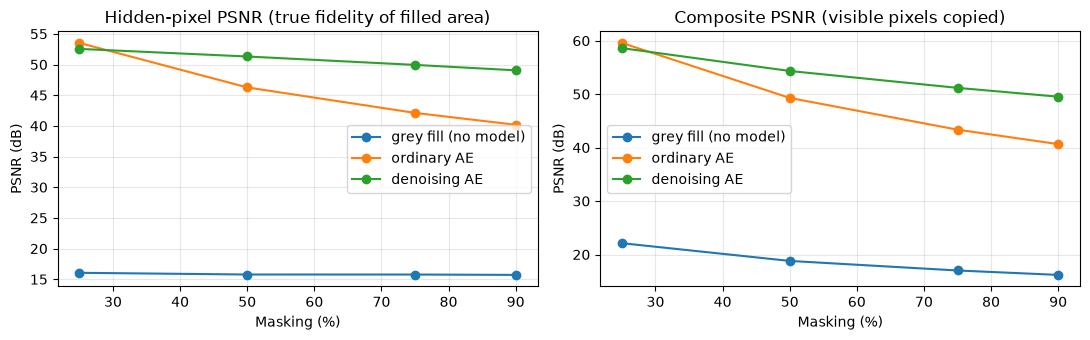

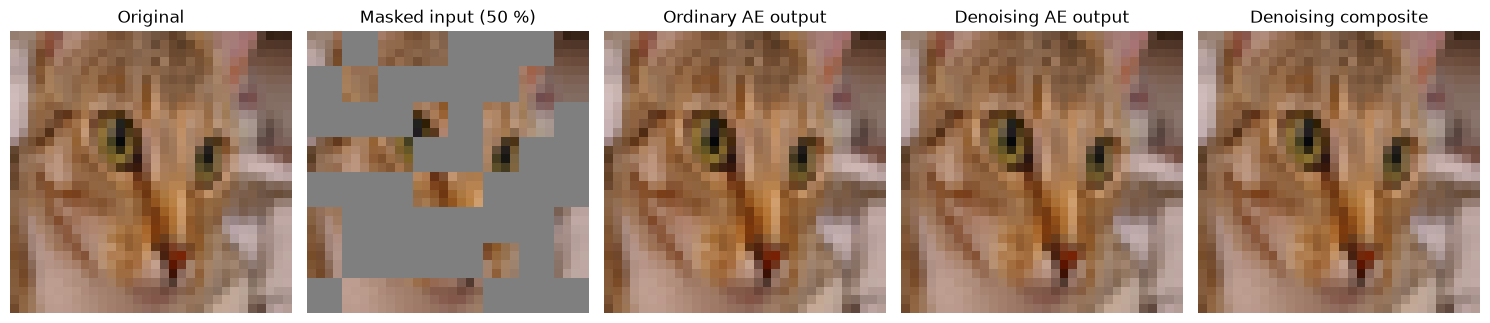

In [17]:
EPOCHS_E = 1500
net_plain = fresh_model(IMAGE_SIZE, 128, 16, 'relu', 17)
net_dn = fresh_model(IMAGE_SIZE, 128, 16, 'relu', 17)
loss_plain, _ = fit(net_plain, clean_test, EPOCHS_E, IMAGE_SIZE, denoise_pct=0, seed=1)
loss_dn, _ = fit(net_dn, clean_test, EPOCHS_E, IMAGE_SIZE, denoise_pct=40, seed=1)
print(f'Final training MSE  ordinary: {loss_plain[-1]:.2e}   denoising: {loss_dn[-1]:.2e}  (denoising must also repair damaged input)')

def block_mask(size, pct, seed, block=4):
    g = size // block
    bm = np.random.default_rng(seed).random((g, g)) < pct / 100
    return np.repeat(np.repeat(bm, block, 0), block, 1)

def masked_eval(m, img, pct, seeds):
    S = img.shape[0]; acc = []
    for sd in seeds:
        mask = block_mask(S, pct, sd)
        masked = img.copy(); masked[mask] = 0.5
        if m is None:                                  # grey-fill baseline
            pred = masked.copy()
        else:
            pred = reconstruct(m, to_tensor(masked[None]), S)[0]
        comp = img.copy(); comp[mask] = pred[mask]
        acc.append(calculate_stats(img, pred, mask, comp))
    return {k: float(np.nanmean([a[k] for a in acc])) for k in acc[0]}

LEVELS_E, TEST_SEEDS = [25, 50, 75, 90], range(100, 120)
rows_E = []
for pct in LEVELS_E:
    for name, mdl in [('grey fill (no model)', None), ('ordinary AE', net_plain), ('denoising AE', net_dn)]:
        rows_E.append(dict(mask_percent=pct, model=name, **masked_eval(mdl, selected_rgb, pct, TEST_SEEDS)))
print(f'\n{"mask":>5} {"model":22s} {"hidden PSNR":>12} {"composite PSNR":>15} {"composite SSIM":>15}')
for r in rows_E:
    print(f'{r["mask_percent"]:4d}% {r["model"]:22s} {r["hidden_psnr"]:12.2f} {r["composite_psnr"]:15.2f} {r["composite_ssim"]:15.3f}')
save_csv('experiment_E_ordinary_vs_denoising.csv', rows_E)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name in ['grey fill (no model)', 'ordinary AE', 'denoising AE']:
    sub = [r for r in rows_E if r['model'] == name]
    axes[0].plot(LEVELS_E, [r['hidden_psnr'] for r in sub], '-o', label=name)
    axes[1].plot(LEVELS_E, [r['composite_psnr'] for r in sub], '-o', label=name)
axes[0].set(xlabel='Masking (%)', ylabel='PSNR (dB)', title='Hidden-pixel PSNR (true fidelity of filled area)')
axes[1].set(xlabel='Masking (%)', ylabel='PSNR (dB)', title='Composite PSNR (visible pixels copied)')
for ax in axes: ax.grid(alpha=.3); ax.legend()
plt.tight_layout(); plt.show()

# Visual: 50 % mask, test seed 107
mask = block_mask(IMAGE_SIZE, 50, 107); masked = selected_rgb.copy(); masked[mask] = 0.5
views, titles = [selected_rgb, masked], ['Original', 'Masked input (50 %)']
for name, mdl in [('Ordinary AE output', net_plain), ('Denoising AE output', net_dn)]:
    views.append(reconstruct(mdl, to_tensor(masked[None]), IMAGE_SIZE)[0]); titles.append(name)
comp = selected_rgb.copy(); comp[mask] = views[-1][mask]; views.append(comp); titles.append('Denoising composite')
fig, axes = plt.subplots(1, 5, figsize=(15, 3.4))
for ax, v, t in zip(axes, views, titles): ax.imshow(np.clip(v, 0, 1), interpolation='nearest'); ax.set_title(t); ax.axis('off')
plt.tight_layout(); plt.show()

## Experiment F — generalisation to an unseen photograph (Q8, and the caution in Section 12)
FCNN-AEs are trained from scratch, so they have no prior about natural images beyond what they see in training. We train on **cat, coffee and rocket** (3 images, 1500 epochs, `relu`, 128 hidden units) and test on the **astronaut**, which the network never saw. The *training-set mean image* is shown as a trivial "knows nothing" baseline.

 latent  PSNR on 3 TRAINING images   PSNR on UNSEEN astronaut  SSIM unseen
     16                      87.01                      10.52        0.062
     64                      75.21                      10.52        0.058
mean-image baseline on unseen astronaut: PSNR 10.44 dB, SSIM 0.017


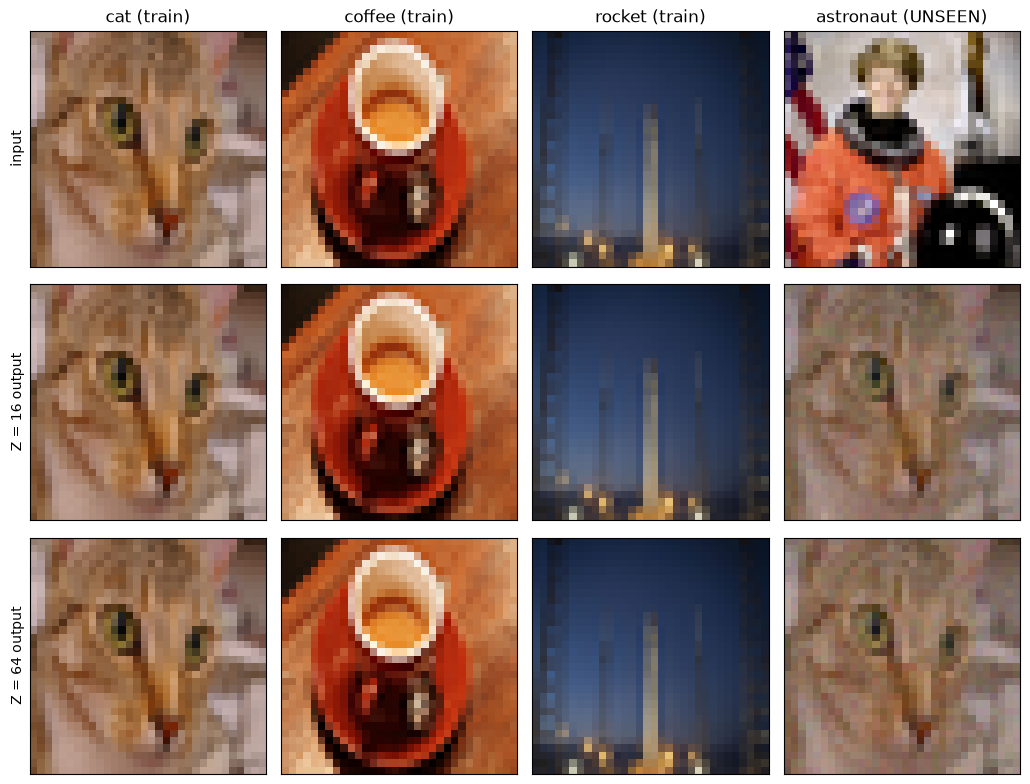

In [18]:
names = list(SAMPLES)
train_names = [n for n in names if n != 'sample_astronaut']
tr_imgs = np.stack([np.asarray(make_rgb(SAMPLES[n], IMAGE_SIZE), dtype=np.float32) / 255.0 for n in train_names])
unseen = np.asarray(make_rgb(SAMPLES['sample_astronaut'], IMAGE_SIZE), dtype=np.float32) / 255.0
Xtr_f, Xun_f = to_tensor(tr_imgs), to_tensor(unseen[None])
mean_img = tr_imgs.mean(0)
q_base = quality(unseen, mean_img)
rows_F, models_F = [], {}
for Z in (16, 64):
    m = fresh_model(IMAGE_SIZE, 128, Z, 'relu', 400 + Z)
    fit(m, Xtr_f, 1500, IMAGE_SIZE, seed=Z)
    models_F[Z] = m
    tr_pred = reconstruct(m, Xtr_f, IMAGE_SIZE); un_pred = reconstruct(m, Xun_f, IMAGE_SIZE)[0]
    rows_F.append(dict(latent=Z, train_psnr=float(np.mean([quality(a, b)['psnr'] for a, b in zip(tr_imgs, tr_pred)])),
                       unseen_psnr=quality(unseen, un_pred)['psnr'], unseen_ssim=quality(unseen, un_pred)['ssim']))
print(f'{"latent":>7} {"PSNR on 3 TRAINING images":>26} {"PSNR on UNSEEN astronaut":>26} {"SSIM unseen":>12}')
for r in rows_F: print(f'{r["latent"]:7d} {r["train_psnr"]:26.2f} {r["unseen_psnr"]:26.2f} {r["unseen_ssim"]:12.3f}')
print(f'{"mean-image baseline on unseen astronaut:":>34} PSNR {q_base["psnr"]:.2f} dB, SSIM {q_base["ssim"]:.3f}')
save_csv('experiment_F_generalisation.csv', rows_F)

cols = len(train_names) + 1
fig, axes = plt.subplots(3, cols, figsize=(2.6 * cols, 8))
for j, n in enumerate(train_names):
    axes[0, j].imshow(tr_imgs[j], interpolation='nearest'); axes[0, j].set_title(n.replace('sample_', '') + ' (train)')
    axes[1, j].imshow(np.clip(reconstruct(models_F[16], Xtr_f[j:j + 1], IMAGE_SIZE)[0], 0, 1), interpolation='nearest')
    axes[2, j].imshow(np.clip(reconstruct(models_F[64], Xtr_f[j:j + 1], IMAGE_SIZE)[0], 0, 1), interpolation='nearest')
axes[0, -1].imshow(unseen, interpolation='nearest'); axes[0, -1].set_title('astronaut (UNSEEN)')
axes[1, -1].imshow(np.clip(reconstruct(models_F[16], Xun_f, IMAGE_SIZE)[0], 0, 1), interpolation='nearest')
axes[2, -1].imshow(np.clip(reconstruct(models_F[64], Xun_f, IMAGE_SIZE)[0], 0, 1), interpolation='nearest')
axes[1, 0].set_ylabel('Z = 16 output'); axes[2, 0].set_ylabel('Z = 64 output'); axes[0, 0].set_ylabel('input')
for ax in axes.ravel(): ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

## 12. Suggested student questions (report / viva)
1. Starting from a `16×16×3` image, why are there **768 input values**? Why is this **not** the same concept as ViT-Base's embedding dimension 768?
2. Show the matrix shapes and calculate weights/biases for `D→H→Z→H→D`. Compare `IMAGE_SIZE=16` and `32`.
3. Compare the decoded picture **before epoch 1** and after 20/100/300 epochs. Explain what backprop updates and what it does **not** change.
4. Test latent dimensions **2, 8, 32** with the same architecture/training. Which retains more detail? Why isn't the relationship always monotonic?
5. Test `relu`, `tanh`, `sigmoid`. Why must the experiment be repeated from reset weights for a fair comparison?
6. Compare ordinary AE and **denoising AE** at 50% masking. Which is trained to accept incomplete images?
7. Why are **hidden MSE / PSNR** more informative than composite PSNR for missing pixels?
8. Compare Lab 11A pretrained **ViT-MAE** with Lab 11B trained-from-scratch **FCNN-AE**: patch tokens, attention, training regime, decoder, latent features, failure modes.

**Caution about face occlusion:** A hand covering a face is present as image content. Masking the hand-covered location does not reveal the actual hidden facial identity. Neither FCNN-AE nor MAE can reliably infer its true pixels.

**Educational interpretation:** This exercise teaches actual network training, **not** high-fidelity image synthesis. Small fully connected AEs can memorize a small image; MAE uses a pretrained Transformer trained on vast image collections.

---
## 13. Answers to the viva questions
Numbers quoted below are from the run stored in this notebook (fixed seeds; a rerun on another machine may differ in the last digits, but not in the trends). Experiment letters refer to the cells above.

**Q1. Why does a `16×16×3` image give 768 inputs, and why is this not ViT-Base's 768?**
The image has 16 rows × 16 columns × 3 colour channels = 768 scalar values. A fully connected network has no notion of rows or columns, so *flatten* simply lays all 768 numbers in one vector and each becomes one input neuron. In ViT-Base, 768 is the **embedding (hidden) dimension**: each 16×16 patch is passed through a *learned* linear projection and becomes one token vector of length 768, and the whole image is a *sequence* of such tokens (196 for a 224×224 picture). The numbers coincide only because a 16×16×3 patch also has 768 raw values; the FCNN's 768 are raw pixel-channel intensities of the entire image, whereas ViT's 768 are learned features per token. Section 11 (pooling) also shows that 768 can arise from `32×32×3` pooled to `16×16×3`, again raw pooled colours.

**Q2. Matrix shapes and parameter counts for `D→H→Z→H→D` (Experiment A).**
Weight matrices (out × in): `H×D`, `Z×H`, `H×Z`, `D×H`; biases: `H`, `Z`, `H`, `D`. Total = `2DH + 2HZ + 2H + Z + D`.

| IMAGE_SIZE | D | H | Z | parameters |
|---|---|---|---|---|
| 16 | 768 | 128 | 16 | **201,744** |
| 32 | 3,072 | 128 | 16 | **793,872** |

The formula matches PyTorch's own count exactly. Doubling the image side quadruples D, and parameters grow by 3.94×, because only the two layers that touch the pixel vector (`enc1`, `dec2`; about 99 % of all parameters) depend on D; the latent layers are unchanged.

**Q3. Decoded picture at epoch 0, 20, 100, 300; what backprop updates (Experiment B).**
At epoch 0 (random weights) the output is a meaningless smooth colour wash (PSNR 15.7 dB, SSIM 0.10). After the first update it is even slightly worse (15.0 dB): one Adam step at learning rate 0.003 can overshoot before the weights settle. Then it improves quickly: epoch 20 → 32.2 dB (SSIM 0.97), epoch 100 → 56.0 dB, epoch 300 → 67.8 dB (MSE 1.7×10⁻⁷). Beyond ~100 epochs the picture is visually identical to the original, so the further gain is invisible; the network has simply **memorised one image**.
Backprop computes ∂loss/∂parameter by the chain rule and the optimizer changes **all eight weight and bias tensors** (the table in Experiment B shows non-zero change in every one). It does **not** change the architecture (layer shapes), the activation function, the learning rate, the number of epochs, the loss function, or the training image/target; those are fixed by the student or by the data.

**Q4. Latent dimension 2, 8, 32 — which keeps more detail and why not always monotonic? (Experiment C)**
* *One training image (C1):* every size from 2 to 64 reaches 63–67 dB and the differences (≤3 dB) are inside the seed-to-seed spread (std up to 3.9 dB). One image needs only a constant answer from the decoder, so even a very small latent is not a bottleneck. Here the "ranking" is optimisation noise, not capacity.
* *160 different crops (C2):* now the latent has to separate many images and training PSNR rises steadily with Z (18.6 dB at Z=2 → 22.6 at Z=8 → 26.2 at Z=32 → 27.3 at Z=64). Z=2 gives only a blurry average colour, Z=8 keeps coarse shapes, Z=64 keeps the most training detail. So a larger latent retains more detail *of the training images*.
* *Why not always monotonic:* (i) with equal epochs and learning rate, different sizes optimise differently and random initialisation matters (C1); (ii) extra capacity beyond what the data needs adds nothing (C1); (iii) extra capacity mainly helps **memorisation**: held-out PSNR hardly moves (17.2 → 18.0 dB from Z=2 to 64) and the Z=64 decodes of held-out crops look noisy, i.e. overfitted. No regulariser (weight decay, noise, KL term) limits that.

**Q5. `relu`, `tanh`, `sigmoid`; why repeat from reset weights? (Experiment D)**
All three reach about 67–70 dB, and MSE < 10⁻³ after 16–18 epochs on average (relu 18.0, tanh 16.0, sigmoid 18.3). On this easy memorisation task, with a shallow network, the differences are small compared with the seed spread, so I do not claim a winner; on deeper networks or harder data they would differ (e.g. sigmoid saturates and gives small gradients). The comparison must start from reset weights because a network already trained with one activation carries weights tuned to it (and Adam's moment estimates), which would give that run a head start and make the comparison unfair. Every run therefore starts from newly drawn weights with the *same* seed, data, learning rate and epochs, so the activation is the only difference; repeating over 3 seeds shows how much a different random start alone changes the result.

**Q6. Ordinary AE vs denoising AE at 50 % masking (Experiment E).**
At 50 % masking the **denoising AE** fills the hidden blocks better: hidden PSNR 51.3 dB vs 46.3 dB for the ordinary AE (grey fill with no model: 15.8 dB). The gap widens with masking (90 %: 49.1 vs 40.2 dB) and reverses slightly at 25 % (52.6 vs 53.5 dB), where the input is almost the complete image that the ordinary AE trained on, while the denoising AE's training loss is higher (1.6×10⁻⁶ vs 6.7×10⁻⁹) because it also has to repair damaged input. **The denoising AE is the one trained to accept incomplete images**: during training it always sees masked inputs and is scored against the full image. Honest caveat: the ordinary AE also does far better than grey fill here (40–54 dB) because it memorised this single image and a few visible blocks are enough to trigger the memorised output; on images it has not memorised neither model can do this (Experiment F).

**Q7. Why hidden MSE/PSNR are more informative than composite PSNR (Experiments E and Section 9).**
Hidden metrics score only pixels the network had to generate. The composite copies the visible pixels, which have zero error, so it mixes in a large "free" area, and its value depends on how much of the image is visible. Examples from the table: the do-nothing grey fill gets composite PSNR 22.1 dB at 25 % masking although its hidden PSNR is 16.1 dB; at 50 % masking the ordinary and denoising AEs have composite SSIM 0.999 vs 1.000 (almost indistinguishable) yet their hidden PSNR differs by 5 dB. Composite scores therefore look optimistic and compress differences between methods and between mask levels; hidden PSNR measures exactly the reconstruction of missing content.

**Q8. Lab 11A pretrained ViT-MAE vs Lab 11B FCNN-AE from scratch.**

| Aspect | ViT-MAE (Lab 11A) | FCNN-AE (Lab 11B) |
|---|---|---|
| Input handling | Image split into 16×16 patches; ~75 % of patches are masked and dropped | Whole image flattened to one vector (3·H·W); masking is optional and applied by us as grey blocks |
| Tokens | One 768-d embedding per patch, plus position embeddings | No tokens, no positional information; every pixel-channel is a separate input |
| Attention | Self-attention lets every visible patch exchange information with all others | None. Dense layers apply fixed learned weights to the whole vector, with no weight sharing across positions |
| Training regime | Pretrained by self-supervision on a very large image collection (ImageNet scale) and used as is | Random weights, trained here for 180–1500 epochs on 1–4 tiny images |
| Decoder | Light Transformer decoder that inserts learnable mask tokens and predicts the missing patches | Dense `Z→H→D` decoder with sigmoid output |
| Latent features | A set of per-patch features (spatial, ~10⁸ parameters in total) | A single global vector (`Z=16` numbers); 0.79 M parameters at 32×32 |
| Failure modes | Plausible but blurry or generic fill-in; cannot recover the true hidden content | Memorisation; fails on unseen images |

Experiment F shows the FCNN's failure mode: on the three training photographs PSNR is 75–87 dB, but on the **unseen astronaut it scores 10.5 dB / SSIM 0.06, no better than simply outputting the average of the training images** (10.4 dB / 0.02), and the output looks like a washed-out blend of the training pictures. The pretrained MAE carries a prior learned from millions of images, so it can reconstruct unseen photographs plausibly.

**Caution about face occlusion.** If a hand covers a face, the hand is real image content. Masking the hand's location tells the model nothing about the true face behind it: a pretrained MAE would produce a plausible face-like fill, and the FCNN-AE would produce an average of what it was trained on. Neither can recover the real hidden pixels or identity.

---
## 14. Conclusion
* The FCNN-AE pipeline (RGB image → flatten → dense encoder → latent vector → dense decoder → reshape) learns from random weights: the loss falls from about 2.7×10⁻² to about 10⁻⁶ within roughly 150 epochs on the selected image, and backprop changes all weights and biases but nothing else.
* Parameter count is dominated by the layers that touch the pixel vector, so it grows almost 4× from 16×16 to 32×32.
* Latent size matters only when the network has to represent many different images; with one image it is irrelevant, and with many images it mostly increases memorisation of the training set. The activation function made no clear difference on this easy task.
* Denoising training makes the network usable on incomplete input, and hidden-pixel PSNR is the metric that shows it.
* All the very high PSNR values (above ~50 dB) come from **memorising the training image(s)**. On a photograph never seen in training the FCNN-AE is no better than the average image (Experiment F), which is why a pretrained ViT-MAE with attention and a learned image prior is the right tool for general image completion.


In [19]:
print('Files written to', OUTDIR.resolve())
for p in sorted(OUTDIR.iterdir()): print('  ', p.name)

Files written to /private/tmp/claude-502/-Users-Suyash-Desktop-Quizerr/1600d1fe-cca2-4349-9b91-4e34faa1e390/scratchpad/run/lab11b_fcnn_outputs
   composite_mask25_seed7.png
   composite_mask50_seed7.png
   composite_mask75_seed7.png
   composite_mask90_seed7.png
   experiment_A_parameters.csv
   experiment_B_epochs.csv
   experiment_C1_latent_single_image.csv
   experiment_C2_latent_dataset.csv
   experiment_D_activations.csv
   experiment_E_ordinary_vs_denoising.csv
   experiment_F_generalisation.csv
   masking_comparison.csv
